# PART 1: SETUP AND TRAINING DATA

In [1]:
# !pip install psutil

In [2]:
# ============================================================
# CELL 0: TRAINING PRESETS
# ============================================================
# Choose how long you want to train the model.
#
# quick:     Verify that the model works.
# classroom: Observe learning during class.
# extended:  Experiment with additional training.
# ============================================================

TRAINING_MODE = "classroom"

TRAINING_PRESETS = {
    "quick": 50,
    "classroom": 30000, #30000
    "extended": 1000
}

TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]

print("Training mode:", TRAINING_MODE)
print("Training steps:", TRAINING_STEPS)

Training mode: classroom
Training steps: 30000


In [3]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURE THE ENVIRONMENT
# ============================================================
# Purpose:
# We are building a Transformer language model FROM SCRATCH.
#
# Unlike our earlier Hugging Face experiments, we will NOT use:
#   - AutoTokenizer.from_pretrained()
#   - AutoModelForCausalLM.from_pretrained()
#   - Pretrained model weights
#
# Instead, we will:
#   1. Create our own tokenizer.
#   2. Define our own neural network architecture.
#   3. Initialize model parameters randomly.
#   4. Train the parameters using text.
#   5. Generate new text using the trained model.
#
# PyTorch provides:
#   - Tensors and numerical operations
#   - Neural network layers
#   - Automatic differentiation (backpropagation)
#   - Optimization algorithms
#
# We use CPU by default so students with M1 Macs, Intel Macs,
# and Windows laptops can run the same notebook.
# ============================================================

import math
import random
import time
import platform
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM

# Reproducibility: initialize random-number generators.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Keep execution predictable on student laptops.
torch.set_num_threads(2)

DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.10.0+cpu
Device: cpu


In [4]:
# ============================================================
# CELL 2: CONFIGURE THE TRANSFORMER ARCHITECTURE
# ============================================================
# Purpose:
# Define the size and training settings of our language model.
#
# VOCAB_SIZE:
#   Number of unique characters in our training corpus.
#   We will calculate this automatically in a later cell.
#
# EMBEDDING_DIM:
#   Number of numerical features used to represent each token.
#
# NUM_HEADS:
#   Number of attention heads in each Transformer block.
#
# NUM_LAYERS:
#   Number of Transformer blocks stacked together.
#
# FEEDFORWARD_DIM:
#   Hidden dimension of the feed-forward neural network.
#
# CONTEXT_LENGTH:
#   Maximum number of tokens the model can examine at once.
#
# BATCH_SIZE:
#   Number of training sequences processed together.
#
# TRAINING_STEPS:
#   Number of parameter-update iterations.
# ============================================================

BATCH_SIZE = 16          # First used: Cell 6B
CONTEXT_LENGTH = 32

# Cell 2
EMBEDDING_DIM = 48       # First used: Cell 7A

# Cell 2: Configurations
NUM_HEADS = 2 #part 2 assignment 7
NUM_LAYERS = 2
FEEDFORWARD_DIM = 192


# Cell 2
LEARNING_RATE = 0.001

# Embedding dimension must be divisible by attention heads.
assert EMBEDDING_DIM % NUM_HEADS == 0

HEAD_DIM = EMBEDDING_DIM // NUM_HEADS

print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Dimension per head:", HEAD_DIM)       #24
print("Transformer blocks:", NUM_LAYERS)
print("Context length:", CONTEXT_LENGTH)

Embedding dimension: 48
Attention heads: 2
Dimension per head: 24
Transformer blocks: 2
Context length: 32


# PART 2: TOKENIZATION

In [5]:
# ============================================================
# CELL 3: CREATE OR LOAD TRAINING DATA
# ============================================================
# Purpose:
# Language models learn statistical patterns from text.
#
# During training, the model repeatedly sees sequences and
# attempts to predict the next character.
#
# For example:
#
# INPUT:  "student"
# TARGET: "tudents"
#
# We will use a small fictional corpus related to INFO 490.
#
# IMPORTANT:
# Repeating a small dataset helps demonstrate learning, but
# it does NOT create the linguistic knowledge of a real LLM.
#
# Students can replace training_corpus.txt with their own
# plain-text dataset before running this cell.
# ============================================================

CORPUS_PATH = Path("training_corpus.txt")  # Relative to the kernel working directory.

if not CORPUS_PATH.exists():
    sentences = [                                               # hypothetical character count
        "students build django applications.",                  # 32 characters, Batch-1
        "students learn python programming.",                   # 32 characters, Batch-2
        "students develop artificial intelligence systems.",    # 32 characters, Batch-3
        "language models predict the next token.",              # 32 characters, Batch-4.....
        "transformers use attention mechanisms.",
        "neural networks learn from training data.",
        "machine learning models contain parameters.",
        "the professor teaches artificial intelligence.",
        "students create innovative startup applications.",
        "django applications use models and views.",
        "training changes the weights of a neural network.",
        "inference uses previously learned parameters.",
        "the university offers courses in informatics.",
        "students experiment with language models.",
        "artificial intelligence can generate text.",
        "the model predicts characters using probabilities.",
        "attention helps models use contextual information.",
        "python is useful for machine learning research.",
        "the students are building useful software products.",
        "small language models can run on local computers."
    ]

    text = "\n".join(sentences)
    CORPUS_PATH.write_text((text + "\n") * 100, encoding="utf-8")

text = CORPUS_PATH.read_text(encoding="utf-8")

print("Characters in corpus:", len(text))
print("\nSample:\n")
print(text[:500])

Characters in corpus: 90300

Sample:

students build django applications.
students learn python programming.
students develop artificial intelligence systems.
language models predict the next token.
transformers use attention mechanisms.
neural networks learn from training data.
machine learning models contain parameters.
the professor teaches artificial intelligence.
students create innovative startup applications.
django applications use models and views.
training changes the weights of a neural network.
inference uses previously 


In [6]:
# ============================================================
# CELL 4: BUILD OUR OWN TOKENIZER
# ============================================================
# Purpose:
# Computers cannot directly perform neural-network operations
# on strings such as "students build django".
#
# We must convert text into numerical token IDs.
#
# Modern LLMs commonly use subword tokenizers.
# For simplicity, our model uses CHARACTER-LEVEL tokenization.
#
# Example:
#
# "cat" → ["c", "a", "t"] → [3, 1, 20]
#
# We create two dictionaries:
#
# stoi = string to integer
# itos = integer to string
#
# These allow encoding and decoding.
# ============================================================

chars = sorted(set(text))
VOCAB_SIZE = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

sample = "students"

def encode(s):
    """Convert a string into a list of character token IDs."""
    # return [stoi[ch] for ch in s]
    return [stoi[ch] for ch in s if ch in stoi]

def decode(ids):
    """Convert character token IDs back into a string."""
    return "".join(itos[int(i)] for i in ids)


print("Vocabulary size:", VOCAB_SIZE)
print("Original:", sample)
print("Encoded:", encode(sample))
print("Decoded:", decode(encode(sample)))

Vocabulary size: 27
Original: students
Encoded: [20, 21, 22, 6, 7, 16, 21, 20]
Decoded: students


In [7]:
# ============================================================
# CELL 5A: CONVERT TRAINING TEXT INTO PYTORCH TENSORS
# ============================================================
# Purpose:
# Convert the entire corpus into a sequence of token IDs.
#
# A tensor is a multidimensional numerical data structure.
#
# Here, our data is initially a one-dimensional tensor:
#
# [12, 4, 7, 2, 9, ...]
#
# Each number represents one character in the corpus.
#
# We also divide the corpus into training and validation sets.
# Training data updates the weights.
# Validation data evaluates performance on held-out sequences.
# ============================================================

data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.9 * len(data))

train_data = data[:split]
val_data = data[split:]

print("Tensor shape:", data.shape)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("First 20 token IDs:", data[:20])

Tensor shape: torch.Size([90300])
Training tokens: 81270
Validation tokens: 9030
First 20 token IDs: tensor([20, 21, 22,  6,  7, 16, 21, 20,  1,  4, 22, 11, 14,  6,  1,  6, 12,  3,
        16,  9])


In [8]:
# ============================================================
# CELL 5B: NUMPY CPU VS. PYTORCH GPU PERFORMANCE (Tutorial)
# ============================================================
# Purpose:
# Compare numerical computation on CPU vs. GPU.
#
# NumPy:
#   Performs matrix multiplication on the CPU.
#
# PyTorch:
#   Can perform matrix multiplication on the GPU.
#
# Apple Silicon:
#   MPS = Metal Performance Shaders (Apple GPU).
#
# EXPERIMENT:
#   1. Create matrices of different sizes.
#   2. Perform the same calculation using NumPy and PyTorch.
#   3. Measure execution time.
#   4. Compare CPU vs. GPU performance.
#
# IMPORTANT:
# GPUs are not always faster for small calculations.
# ============================================================

# Select Apple GPU if available.
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

results = []

for size in [100, 500, 1000, 2000]:

    # Create identical matrices for both libraries.
    A = np.random.rand(size, size).astype(np.float32)
    B = np.random.rand(size, size).astype(np.float32)

    A_gpu = torch.from_numpy(A).to(DEVICE)
    B_gpu = torch.from_numpy(B).to(DEVICE)

    # Warm up the GPU before measuring.
    for _ in range(3):
        _ = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    # NumPy CPU calculation.
    start = time.perf_counter()
    numpy_result = A @ B
    cpu_time = time.perf_counter() - start

    # PyTorch GPU calculation.
    start = time.perf_counter()
    torch_result = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    gpu_time = time.perf_counter() - start

    results.append({
        "Matrix Size": f"{size} × {size}",
        "NumPy CPU (ms)": round(cpu_time * 1000, 2),
        "PyTorch GPU (ms)": round(gpu_time * 1000, 2),
        "GPU Speedup": round(cpu_time / gpu_time, 2)
    })

# Display comparison.
results_df = pd.DataFrame(results)

print("DEVICE:", DEVICE.upper())
print("\nCPU VS. GPU PERFORMANCE")
display(results_df)

DEVICE: CPU

CPU VS. GPU PERFORMANCE


,Matrix Size,NumPy CPU (ms),PyTorch GPU (ms),GPU Speedup
0,100 × 100,0.05,0.02,2.61
1,500 × 500,0.73,1.05,0.70
2,1000 × 1000,2.91,7.38,0.39
3,2000 × 2000,19.22,59.03,0.33


In [9]:
# ============================================================
# CELL 6A: CREATE INPUT AND TARGET SEQUENCES (Tutorial)
# ============================================================
# Purpose:
# A causal language model learns to predict the NEXT token.
#
# We train it using two sequences:
#
# INPUT:  characters 0 through N-1
# TARGET: characters 1 through N
#
# The target sequence is shifted one position forward.
#
# Example:
#
# INPUT:  "studen"
# TARGET: "tudent"
#
# At each position, the model predicts the following character.
# ============================================================

sample = train_data[:CONTEXT_LENGTH + 1]

x = sample[:-1]
y = sample[1:]

print("INPUT TEXT: ", decode(x))
print("TARGET TEXT:", decode(y))

print("\nINPUT IDs:", x.tolist())
print("TARGET IDs:", y.tolist())

INPUT TEXT:  students build django applicatio
TARGET TEXT: tudents build django application

INPUT IDs: [20, 21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17]
TARGET IDs: [21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17, 16]


In [10]:
# ============================================================
# CELL 6B: CREATE MINI-BATCHES FOR TRAINING (Create Function + Test it)
# ============================================================
# Purpose:
# Training does not require processing the entire corpus
# simultaneously.
#
# Instead, we randomly select small batches of sequences.
#
# WHY MINI-BATCHES?
#
# 1. MEMORY:
#    Processing smaller sequences requires less memory.
#
# 2. COMPUTATION:
#    Shorter sequences reduce attention computation.
#
# 3. LEARNING:
#    The model can update its weights after each mini-batch.
#
# 4. RANDOM SAMPLING:
#    Different batches expose the model to different
#    portions of the training corpus.
#
# OUR CONFIGURATION:
#    Training Corpus = 81,270 tokens
#    Batch Size       = 16 sequences
#    Context Length   = 32 tokens
#
#    Input Shape = (16, 32)
#
# IMPORTANT:
#    We are NOT discarding the remaining training data.
#    It remains available for sampling in future steps.
#
#    Random sampling does not guarantee that every
#    training example will be visited exactly once.
#
# Instead, we randomly select short sequences.
#
# Each batch contains:
#
# BATCH_SIZE sequences
# CONTEXT_LENGTH tokens per sequence
#
# Tensor shape:
#
# (batch_size, context_length)
#
# For our configuration:
#
# (16, 32)
# ============================================================

def get_batch(source):
    """Sample random input/target sequences from a token tensor."""
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch(train_data)

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("\nFirst input:", decode(xb[0]))
print("First target:", decode(yb[0]))

Input batch shape: torch.Size([16, 32])
Target batch shape: torch.Size([16, 32])

First input: tics.
students experiment with l
First target: ics.
students experiment with la


# PART 3: EMBEDDINGS AND PARAMETERS

In [11]:
# ============================================================
# CELL 7A: UNDERSTANDING TOKEN EMBEDDINGS (Creating Object "token_embedding" from Class nm.Embedding in line 30 + Testing it)
# ============================================================
# Purpose:
# Token IDs are arbitrary numerical labels.
#
# For example:
#   "a" might have ID 3.
#   "b" might have ID 4.
#
# These numbers do NOT mean that "b" is mathematically
# greater than "a".
#
# An embedding layer maps each token ID to a learned vector.
#
# Example:
#
# Token ID 3 → [0.12, -0.54, 0.87, ...]
#
# Embedding shape:
#
# (vocabulary_size, embedding_dimension)
#
# Number of parameters:
#
# vocabulary_size × embedding_dimension
# ============================================================

# Cell 7A: Initiating the class
token_embedding = nn.Embedding(VOCAB_SIZE, EMBEDDING_DIM)

# Testing
sample_ids = torch.tensor(encode("student"))
sample_embeddings = token_embedding(sample_ids)

print("Input token IDs:", sample_ids)
print("Embedding shape:", sample_embeddings.shape)

print("Embedding vector for first token:\n", sample_embeddings[0])

print("\nCalculated parameters:", VOCAB_SIZE * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in token_embedding.parameters()))

Input token IDs: tensor([20, 21, 22,  6,  7, 16, 21])
Embedding shape: torch.Size([7, 48])
Embedding vector for first token:
 tensor([ 0.8521, -1.6947,  1.1806, -2.8929, -0.3876, -0.7124, -1.6171, -0.3590,
         0.0514,  0.6950,  1.8352, -1.9180, -1.3924,  0.5405,  0.4351, -2.2717,
        -0.1339, -0.0586,  0.1257, -0.5526,  0.0745, -0.1493, -0.5523, -0.0934,
        -1.0284,  0.4044,  2.1426, -0.5154,  1.0827,  1.2499,  0.9821,  0.2269,
         0.4928, -0.5128,  0.3006,  0.0773,  0.6478, -0.4324,  1.1740,  0.7011,
         0.6674, -0.8036, -1.3776, -0.4410,  0.1418,  1.1085,  0.5544,  1.5818],
       grad_fn=<SelectBackward0>)

Calculated parameters: 1296
Actual parameters: 1296


In [12]:
# ============================================================
# CELL 7B: UNDERSTANDING POSITIONAL EMBEDDINGS
# ============================================================
# Purpose:
# Token embeddings represent token identities.
#
# But the same character can appear at different positions.
#
# Example:
#
# "cat" and "tac" contain the same characters but in
# different orders.
#
# Positional embeddings provide information about WHERE
# each token appears in the sequence.
#
# Our model uses learned positional embeddings.
#
# Number of parameters:
#
# context_length × embedding_dimension
# ============================================================

position_embedding = nn.Embedding(CONTEXT_LENGTH, EMBEDDING_DIM)

positions = torch.arange(CONTEXT_LENGTH)

# Retrieve vectors for requested position ids (can be one or many)
position_vectors = position_embedding(positions)

print("Position IDs:", positions)
print("Position embedding shape:", position_vectors.shape)

print("\nCalculated parameters:", CONTEXT_LENGTH * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in position_embedding.parameters()))

Position IDs: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
Position embedding shape: torch.Size([32, 48])

Calculated parameters: 1536
Actual parameters: 1536


# PART 4: ATTENTION

In [13]:
# ============================================================
# CELL 8A: INTRODUCING QUERY, KEY, AND VALUE PROJECTIONS
# ============================================================
# Purpose:
# Self-attention allows token representations to incorporate
# information from other positions in the sequence.
#
# The model creates three representations:
#
# Query (Q): What information is this position looking for?
# Key (K):   What information can this position match against?
# Value (V): What information can this position contribute?
#
# These are LEARNED linear transformations.
#
# For a simple demonstration, we create three linear layers.
# ============================================================

query_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
key_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
value_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)

# sample_ids = student (7 characters -> Represented as 48 numbers per character -> (7,48))
sample_vectors = token_embedding(sample_ids)
Q = query_layer(sample_vectors)
K = key_layer(sample_vectors)
V = value_layer(sample_vectors)

print("Input shape:", sample_vectors.shape)
print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)


print("\n\nWq shape:", query_layer.weight.shape)
print("bq shape:", query_layer.bias.shape)
# Query weight matrix
print(query_layer.weight)

# Query bias vector
print(query_layer.bias)

Input shape: torch.Size([7, 48])
Query shape: torch.Size([7, 48])
Key shape: torch.Size([7, 48])
Value shape: torch.Size([7, 48])


Wq shape: torch.Size([48, 48])
bq shape: torch.Size([48])
Parameter containing:
tensor([[ 0.0223,  0.1021, -0.1240,  ..., -0.0353,  0.0166,  0.0085],
        [ 0.0927,  0.0924,  0.1188,  ...,  0.1165, -0.1319,  0.1247],
        [ 0.1155,  0.0089, -0.0116,  ..., -0.1092, -0.1263, -0.0002],
        ...,
        [-0.0515, -0.1422,  0.1362,  ..., -0.0531, -0.1135, -0.1129],
        [-0.0667,  0.0230, -0.0167,  ...,  0.0223, -0.0244,  0.0909],
        [ 0.1178,  0.0642,  0.0312,  ...,  0.0113,  0.1333, -0.1056]],
       requires_grad=True)
Parameter containing:
tensor([ 0.0344,  0.0344, -0.0017,  0.1284,  0.0290,  0.0078,  0.0985, -0.0114,
        -0.0093, -0.1190, -0.0009, -0.0674,  0.0836,  0.1256, -0.1347, -0.0836,
         0.1390, -0.0616,  0.1284,  0.1421, -0.0362, -0.1168,  0.0722,  0.0656,
         0.1254,  0.0208,  0.0785, -0.1238,  0.0199,  0.0340,  0.

In [14]:
# ============================================================
# CELL 8B: CALCULATE SELF-ATTENTION SCORES
# ============================================================
# Purpose:
# Attention uses similarity between Query and Key vectors.
#
# The fundamental operation is:
#
# Q × K-transpose
#
# The result contains a score for every pair of positions.
#
# We divide by sqrt(embedding_dimension) to scale the scores.
#
# This is a single-head demonstration.
# The complete Transformer will use multi-head attention.
# ============================================================

# @ represents matrix multiplication
scores = Q @ K.T / math.sqrt(EMBEDDING_DIM)

print("Attention score matrix shape:", scores.shape)
print("\nAttention scores:\n", scores)

Attention score matrix shape: torch.Size([7, 7])

Attention scores:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)


In [15]:
# ============================================================
# CELL 8C: APPLY CAUSAL ATTENTION MASKING
# ============================================================
# Purpose:
# Our language model predicts the NEXT character.
#
# During prediction, a position must not access future tokens.
#
# Otherwise, the model could cheat during training.
#
# A causal mask allows each position to attend only to:
#   - itself
#   - earlier positions
#
# Future positions receive negative infinity before softmax.
#
# Softmax then assigns those positions probability zero.
# ============================================================

T = scores.shape[0]

# STEP 1: Create causal mask.
# 1 = Allowed, 0 = Blocked.
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))

# STEP 2: Replace future attention scores with -inf.
masked_scores = scores.masked_fill(~causal_mask, float("-inf")) # probability is e^value in matrix, e^-inf makes probability become 0

# STEP 3: Apply Softmax.
# -inf becomes 0 probability.
# Remaining probabilities sum to 1.
attention_weights = F.softmax(masked_scores, dim=-1)

# STEP 4: Display results.
print("CAUSAL MASK:\n", causal_mask.int())
print("\nORIGINAL ATTENTION SCORES:\n", scores)
print("\nMASKED SCORES (BEFORE SOFTMAX):\n", masked_scores)
print("\nATTENTION PROBABILITIES (AFTER SOFTMAX):\n", attention_weights)
print("\nROW SUMS:", attention_weights.sum(dim=-1))

CAUSAL MASK:
 tensor([[1, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

ORIGINAL ATTENTION SCORES:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)

MASKED SCORES (BEFORE SOFTMAX):
 tensor([[ 0.5306,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [-0.0142, -0.6923,    -inf,    -inf,    -inf,    -inf,    -inf

# PART 5: BUILD THE TRANSFORMER

In [16]:
# ============================================================
# CELL 9A: BUILD A TRANSFORMER BLOCK
# ============================================================
# Purpose:
# A Transformer block combines:
#
# 1. Multi-head self-attention
# 2. Residual connections
# 3. Layer normalization
# 4. Feed-forward neural network
#
# Multi-head attention allows the model to learn different
# attention patterns simultaneously.
#
# Residual connections help information and gradients flow
# through the network.
#
# Layer normalization stabilizes representations.
#
# The feed-forward network transforms each token's features.
#
# PyTorch provides MultiheadAttention, which implements
# the Q/K/V projections and attention computation.
#
# We use batch_first=True:
# (batch, sequence, embedding_dimension)
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()

        # Main Component 1
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)

        # Supporting Component 1
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        # Main Component 2
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))


    def forward(self, x):

        T = x.shape[1]


        # True means a position is blocked from attention.
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)

        # Supporting Component 2
        # Attention + residual connection.
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)

        # Residual 1: Original representation + attention output
        x = x + attended

        # Residual 2: Updated representation + feed-forward output
        # Feed-forward network + residual connection.
        x = x + self.feedforward(self.ln2(x))

        return x

In [17]:
# ============================================================
# CELL 9B: BUILDING OUR COMPLETE TINY TRANSFORMER
# ============================================================
# Purpose:
# Combine all the components into one language model.
#
# Architecture:
#
# Token IDs
#    ↓
# Token Embeddings + Position Embeddings
#    ↓
# Transformer Block(s)
#    ↓
# Layer Normalization
#    ↓
# Linear Output Layer
#    ↓
# Logits for every vocabulary token
#
# The output tensor has shape:
#
# (batch_size, sequence_length, vocabulary_size)
#
# Each position produces scores for the NEXT character.
# ============================================================

class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])

        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):

        B, T = input_ids.shape

        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)

        return self.output(x)

In [18]:
# ============================================================
# CELL 10A: INITIALIZE OUR TRANSFORMER
# ============================================================
# Purpose:
# Create an instance of the Transformer architecture.
#
# IMPORTANT:
# The model is NOT trained yet.
#
# PyTorch initializes its trainable parameters using its
# default initialization methods.
#
# These parameters have not learned the patterns in our corpus.
#
# We will first inspect the model and its parameter count.
# ============================================================
# This helps ensure that each experiment begins with identical initial weights.
torch.manual_seed(SEED)

model = TinyTransformerLM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    feedforward_dim=FEEDFORWARD_DIM,
    context_length=CONTEXT_LENGTH
).to(DEVICE)

print(model)

TinyTransformerLM(
  (token_embedding): Embedding(27, 48)
  (position_embedding): Embedding(32, 48)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
      )
      (ln1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (feedforward): Sequential(
        (0): Linear(in_features=48, out_features=192, bias=True)
        (1): ReLU()
        (2): Linear(in_features=192, out_features=48, bias=True)
      )
    )
    (1): TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
      )
      (ln1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (feedforward): Sequential(
        (0): Linear(in_features=48, out_fe

In [19]:
# ============================================================
# CELL 10B: CALCULATE TRAINABLE MODEL PARAMETERS
# ============================================================
# Purpose:
# A parameter is a numerical value learned during training.
#
# Examples include:
#   - Embedding values
#   - Attention projection weights
#   - Feed-forward weights
#   - Bias terms
#   - Layer normalization parameters
#
# The total number of parameters is the sum of the number
# of elements in all trainable parameter tensors.
#
# We print the count for each named parameter tensor.
# ============================================================

total_parameters = 0

for name, parameter in model.named_parameters():
    count = parameter.numel()
    total_parameters += count
    print(f"{name:<55} {str(tuple(parameter.shape)):<18} {count:>8,}")

print("=" * 90)
print(f"TOTAL TRAINABLE PARAMETERS: {total_parameters:,}")

token_embedding.weight                                  (27, 48)              1,296
position_embedding.weight                               (32, 48)              1,536
blocks.0.attention.in_proj_weight                       (144, 48)             6,912
blocks.0.attention.in_proj_bias                         (144,)                  144
blocks.0.attention.out_proj.weight                      (48, 48)              2,304
blocks.0.attention.out_proj.bias                        (48,)                    48
blocks.0.ln1.weight                                     (48,)                    48
blocks.0.ln1.bias                                       (48,)                    48
blocks.0.ln2.weight                                     (48,)                    48
blocks.0.ln2.bias                                       (48,)                    48
blocks.0.feedforward.0.weight                           (192, 48)             9,216
blocks.0.feedforward.0.bias                             (192,)              

# PART 6: LOGITS, SOFTMAX, TEMPERATURE, AND TEXT-GENERATION Function

In [20]:
# ============================================================
# CELL 11A: UNDERSTANDING LOGITS (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# The Transformer does not directly output words or
# probabilities.
#
# It produces LOGITS.
#
# Logits are raw numerical scores for possible next tokens.
#
# Example:
#
# Token "a" → 1.8
# Token "b" → -0.4
# Token "c" → 0.9
#
# Higher logits indicate greater preference before softmax.
#
# We will inspect the logits produced by our untrained model.
# ============================================================

model.eval()

with torch.no_grad():
    logits = model(xb)

print("Logits shape:", logits.shape)
print("Expected shape:", (BATCH_SIZE, CONTEXT_LENGTH, VOCAB_SIZE))

# Scores for the final position of the first sequence.
next_token_logits = logits[0, -1]

print("\nFirst 10 logits:")
print(next_token_logits[:10])

Logits shape: torch.Size([16, 32, 27])
Expected shape: (16, 32, 27)

First 10 logits:
tensor([ 0.1745,  0.0648,  0.4874,  0.1475,  0.3546, -1.1070,  0.3530,  0.3240,
        -0.0521,  0.7617])


In [21]:
# ============================================================
# CELL 11B: APPLYING SOFTMAX (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Logits are not probabilities.
#
# Softmax transforms logits into a probability distribution.
#
# Every probability lies between 0 and 1.
# All probabilities sum to 1.
#
# Formula:
#
# P(token_i) = exp(logit_i) / sum(exp(all_logits))
#
# We will inspect the most probable next characters.
# ============================================================

probabilities = F.softmax(next_token_logits, dim=-1)

top_probs, top_ids = torch.topk(probabilities, k=min(10, VOCAB_SIZE))

print("Sum of probabilities:", probabilities.sum().item())

print("\nTop predicted next characters:")

for token_id, probability in zip(top_ids, top_probs):
    print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")

Sum of probabilities: 0.9999998807907104

Top predicted next characters:
'm'      0.0761
'x'      0.0668
'n'      0.0662
'g'      0.0614
'v'      0.0508
'.'      0.0467
'r'      0.0461
'j'      0.0433
'b'      0.0409
't'      0.0408


In [22]:
# ============================================================
# CELL 11C: UNDERSTANDING TEMPERATURE (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Temperature changes the probability distribution used
# when sampling the next token.
#
# Formula:
#
# probabilities = softmax(logits / temperature)
#
# Lower temperature:
#   Makes the distribution more concentrated.
#
# Higher temperature:
#   Makes the distribution flatter.
#
# Temperature does NOT modify model weights.
#
# Temperature = 0 is handled separately through greedy
# decoding rather than division by zero.
# ============================================================

for temperature in [0.2, 0.5, 1.0, 2.0]:

    probs = F.softmax(next_token_logits / temperature, dim=-1)
    top_probs, top_ids = torch.topk(probs, k=5)

    print(f"\nTEMPERATURE = {temperature}")

    for token_id, probability in zip(top_ids, top_probs):
        print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")


TEMPERATURE = 0.2
'm'      0.3308
'x'      0.1724
'n'      0.1651
'g'      0.1134
'v'      0.0438

TEMPERATURE = 0.5
'm'      0.1301
'x'      0.1003
'n'      0.0985
'g'      0.0848
'v'      0.0580

TEMPERATURE = 1.0
'm'      0.0761
'x'      0.0668
'n'      0.0662
'g'      0.0614
'v'      0.0508

TEMPERATURE = 2.0
'm'      0.0546
'x'      0.0511
'n'      0.0509
'g'      0.0490
'v'      0.0446


# PART 7: TEST THE MODEL BEFORE TRAINING

In [23]:
# ============================================================
# CELL 12A: DEFINE TEXT GENERATION (BEFORE TRAINING)
# ============================================================
# Purpose:
# This function works before AND after training.
#
# Now we perform INFERENCE.
#
# Inference means using learned parameters to produce
# predictions without updating the model.
#
# Generation works autoregressively:
#
# 1. Read the current sequence.
# 2. Predict logits for the next character.
# 3. Convert logits into probabilities.
# 4. Sample a character.
# 5. Append it to the sequence.
# 6. Repeat.
#
# max_new_tokens controls how many new characters we generate.
#
# Because our tokenizer is character-level:
#
# ONE TOKEN = ONE CHARACTER.
# ============================================================

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    """
    Generate text autoregressively using our untrained Transformer.

    Parameters
    ----------
    model : TinyTransformerLM
        Untrained language model.
    prompt : str
        Starting text. Characters must exist in the vocabulary.
    max_new_tokens : int
        Number of new characters to generate.
    temperature : float
        Sampling temperature. Must be greater than zero.

    Returns
    -------
    str
        Original prompt plus generated continuation.
    """

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    was_training = model.training
    model.eval()

    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):

        # Keep only the most recent context_length characters.
        context = ids[:, -model.context_length:]

        # Predict logits for every position.
        logits = model(context)

        # Only the final position predicts the next character.
        next_logits = logits[:, -1, :] / temperature

        # Convert logits into probabilities.
        probabilities = F.softmax(next_logits, dim=-1)

        # Sample one character.
        next_id = torch.multinomial(probabilities, num_samples=1)

        # Append the generated character.
        ids = torch.cat([ids, next_id], dim=1)

    if was_training:
        model.train()
    return decode(ids[0].tolist())

In [24]:
# ============================================================
# CELL 12B: GENERATE TEXT BEFORE TRAINING
# ============================================================
# Purpose: Capture what a randomly initialized Transformer produces.
# We will compare this against the same model after training.
# ============================================================

BEFORE_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))


BEFORE TRAINING: 'students mliectgmyjkt\nk.nbp bu.rps.masbdfoe\nf\nvkapkto.empx.jjfwssoaji'


# PART 8: TRAIN THE TRANSFORMER

In [25]:
# ============================================================
# CELL 13A: CALCULATE CROSS-ENTROPY LOSS ON INITIAL TRAINING
# ============================================================
# Purpose:
# Training requires a way to measure prediction error.
#
# We use CROSS-ENTROPY LOSS.
#
# The model predicts a probability distribution over
# possible next characters.
#
# The correct next character is known from our corpus.
#
# Cross-entropy penalizes the model when it assigns a low
# probability to the correct token.
#
# For one prediction:
#
# Loss = -log(P(correct_token))
#
# Lower loss generally means the model assigns more
# probability to the correct training targets.
# ============================================================

def calculate_loss(logits, targets):
    """Calculate next-token cross-entropy loss."""
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

model.train()

logits = model(xb)
loss = calculate_loss(logits, yb)

print("Initial training loss:", loss.item())

Initial training loss: 3.4792845249176025


In [26]:
# ============================================================
# CELL 13B: UNDERSTANDING BACKPROPAGATION
# ============================================================
# Purpose:
# Backpropagation calculates gradients.
#
# A gradient tells us how the loss changes when a parameter
# changes slightly.
#
# PyTorch automatically computes gradients using autograd.
#
# The process:
#
# Input → Model → Logits → Loss → Backpropagation → Gradients
#
# IMPORTANT:
# loss.backward() computes gradients.
# It does NOT update the parameters by itself.
# ============================================================

model.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()

parameter = model.token_embedding.weight

print("Parameter tensor shape:", parameter.shape)
print("Gradient tensor shape:", parameter.grad.shape)
print("Gradient magnitude:", parameter.grad.abs().mean().item())

Parameter tensor shape: torch.Size([27, 48])
Gradient tensor shape: torch.Size([27, 48])
Gradient magnitude: 0.0007680173730477691


In [27]:
# ============================================================
# CELL 13C: UNDERSTANDING THE ADAMW OPTIMIZER
# ============================================================
# Purpose:
# Backpropagation computes gradients.
#
# An optimizer uses those gradients to update model weights.
#
# AdamW is a widely used optimization algorithm.
#
# Training iteration:
#
# 1. Calculate predictions.
# 2. Calculate loss.
# 3. Compute gradients.
# 4. Update parameters.
#
# We will save a copy of one parameter tensor before
# updating it so students can verify that weights change.
# ============================================================

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

weights_before = model.token_embedding.weight.detach().clone()

optimizer.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()
optimizer.step()

weights_after = model.token_embedding.weight.detach().clone()

difference = (weights_after - weights_before).abs().sum()

print("Loss:", loss.item())
print("Total absolute weight change:", difference.item())
print("Training update #1 completed; the next cell continues training.")


Loss: 3.4792845249176025
Total absolute weight change: 1.2004269361495972
Training update #1 completed; the next cell continues training.


# Training Begins

In [28]:
# ============================================================
# CELL 14A: TRAINING OUR TRANSFORMER LANGUAGE MODEL
# ============================================================
# Purpose:
# Repeatedly update the model's parameters to improve
# next-character prediction.
#
# Each iteration:
#
# 1. Sample training sequences.
# 2. Perform a forward pass.
# 3. Calculate cross-entropy loss.
# 4. Compute gradients through backpropagation.
# 5. Update weights using AdamW.
#
# We record training loss so students can observe learning.
#
# This cell is intentionally small enough to run on CPU.
# ============================================================

model.train()

loss_history = []
start_time = time.perf_counter()

for step in range(TRAINING_STEPS):

    xb, yb = get_batch(train_data)

    optimizer.zero_grad()

    logits = model(xb)
    loss = calculate_loss(logits, yb)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if step % 50 == 0 or step == TRAINING_STEPS - 1:
        print(f"Step {step + 1:>4}/{TRAINING_STEPS} | Loss: {loss.item():.4f}")

elapsed = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed:.2f} seconds.")

Step    1/30000 | Loss: 3.3653
Step   51/30000 | Loss: 2.5064
Step  101/30000 | Loss: 2.2421
Step  151/30000 | Loss: 2.1230
Step  201/30000 | Loss: 1.8563
Step  251/30000 | Loss: 1.6082
Step  301/30000 | Loss: 1.4899
Step  351/30000 | Loss: 1.3469
Step  401/30000 | Loss: 1.1302
Step  451/30000 | Loss: 0.9804
Step  501/30000 | Loss: 0.8725
Step  551/30000 | Loss: 0.7905
Step  601/30000 | Loss: 0.7130
Step  651/30000 | Loss: 0.5946
Step  701/30000 | Loss: 0.4682
Step  751/30000 | Loss: 0.4290
Step  801/30000 | Loss: 0.3511
Step  851/30000 | Loss: 0.3428
Step  901/30000 | Loss: 0.3219
Step  951/30000 | Loss: 0.2900
Step 1001/30000 | Loss: 0.2751
Step 1051/30000 | Loss: 0.2838
Step 1101/30000 | Loss: 0.2352
Step 1151/30000 | Loss: 0.1815
Step 1201/30000 | Loss: 0.2310
Step 1251/30000 | Loss: 0.1900
Step 1301/30000 | Loss: 0.1898
Step 1351/30000 | Loss: 0.1877
Step 1401/30000 | Loss: 0.1785
Step 1451/30000 | Loss: 0.1900
Step 1501/30000 | Loss: 0.1885
Step 1551/30000 | Loss: 0.2147
Step 160

In [29]:
# ============================================================
# CELL 14B: SAVE TRAINING RESULTS
# ============================================================
# Purpose:
# Record the performance of each training experiment.
#
# Run this cell after training with:
# quick, classroom, or extended.
#
# Results are saved to CSV and preserved across restarts.
# ============================================================

RESULTS_FILE = Path("training_results.csv")

# Load previous experiments, if available.
results = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()

# Record the current experiment.
new_result = pd.DataFrame([{
    "Mode": TRAINING_MODE,
    "Steps": TRAINING_STEPS,
    "Final Loss": round(loss_history[-1], 4),
    "Generated Text": generate_text(model, "students ", max_new_tokens=40, temperature=0.7)
}])

# Add the new experiment and save.
results = pd.concat([results, new_result], ignore_index=True)
results.to_csv(RESULTS_FILE, index=False)

print("Training experiment saved!")
display(results)

Training experiment saved!


,Mode,Steps,Final Loss,Generated Text
0,classroom,3000,0.1761,students learn python programeters.\nthe unive...
1,classroom,300,1.8387,students uaraticte ciieantimell monterns nprentud
2,classroom,30,2.7440,students s.uitacde ciieantimn ucte teresdnpeces i
3,classroom,30000,0.1284,students learn python programming.\nstudents d...
4,classroom,300,1.9349,students aration wofrs.\ntthearamefe ch.\nstin...
5,classroom,30000,0.1404,students learn python programming.\nstudents d...
6,classroom,30000,0.1404,students learn python programming.\nstudents d...
7,classroom,30000,0.1404,students learn python programming.\nstudents d...
8,classroom,30000,0.1404,students learn python programming.\nstudents d...
9,classroom,30000,0.1392,students build django applications.\nstudents ...


In [30]:
# ============================================================
# CELL 14C: COMPARE TRAINING EXPERIMENTS
# ============================================================
# Purpose:
# Compare model performance across training presets.
# No retraining required.
# ============================================================

results = pd.read_csv("training_results.csv")

print("TRAINING PERFORMANCE COMPARISON")
display(results)

TRAINING PERFORMANCE COMPARISON


,Mode,Steps,Final Loss,Generated Text
0,classroom,3000,0.1761,students learn python programeters.\nthe unive...
1,classroom,300,1.8387,students uaraticte ciieantimell monterns nprentud
2,classroom,30,2.7440,students s.uitacde ciieantimn ucte teresdnpeces i
3,classroom,30000,0.1284,students learn python programming.\nstudents d...
4,classroom,300,1.9349,students aration wofrs.\ntthearamefe ch.\nstin...
5,classroom,30000,0.1404,students learn python programming.\nstudents d...
6,classroom,30000,0.1404,students learn python programming.\nstudents d...
7,classroom,30000,0.1404,students learn python programming.\nstudents d...
8,classroom,30000,0.1404,students learn python programming.\nstudents d...
9,classroom,30000,0.1392,students build django applications.\nstudents ...


In [31]:
# ============================================================
# CELL 14D: SAVE OUR TRAINED MODEL
# ============================================================
# Purpose:
# Our model's parameters changed during training.
#
# If we close the Jupyter kernel, the model object in RAM
# disappears.
#
# Therefore, we save:
#
# 1. The model's learned parameters (state_dict).
# 2. The architecture configuration.
# 3. The tokenizer vocabulary.
#
# Unlike Hugging Face's save_pretrained(), this is a custom
# PyTorch model, so we use torch.save().
#
# IMPORTANT:
# Do not push large model checkpoints to GitHub.
# ============================================================

CHECKPOINT_PATH = Path("tiny_transformer.pt")

checkpoint = {
    "model_state": model.state_dict(),
    "vocab": chars,
    "config": {
        "embedding_dim": EMBEDDING_DIM,
        "num_heads": NUM_HEADS,
        "num_layers": NUM_LAYERS,
        "feedforward_dim": FEEDFORWARD_DIM,
        "context_length": CONTEXT_LENGTH
    }
}

torch.save(checkpoint, CHECKPOINT_PATH)

print("Model saved to:", CHECKPOINT_PATH)

Model saved to: tiny_transformer.pt


In [32]:
# ============================================================
# CELL 14E: RELOAD OUR TRAINED MODEL
# ============================================================
# Purpose:
# Demonstrate that a trained model can be reconstructed
# from its saved architecture configuration and weights.
#
# We create a NEW model object and load the saved parameters.
#
# This is conceptually similar to what happens when
# Hugging Face loads pretrained weights.
#
# The saved vocabulary must match the vocabulary used
# during training.
# ============================================================

CHECKPOINT_PATH = Path("tiny_transformer.pt")

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")
print(generate_text(reloaded_model, "students ", max_new_tokens=100))

Model reloaded successfully.
students are building useful software products.
small language models can run on local computers.
students bu


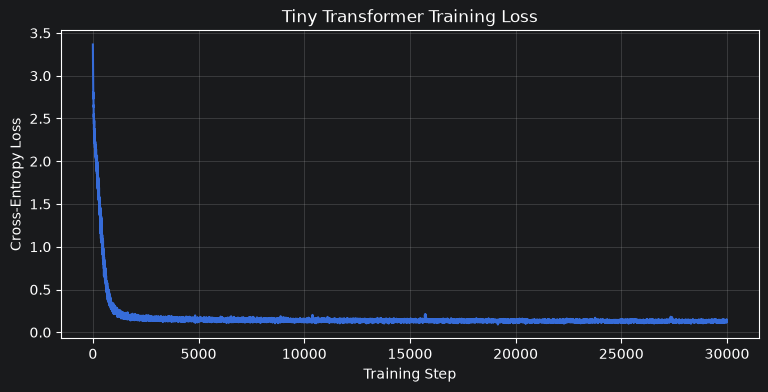

In [33]:
# ============================================================
# CELL 14F: VISUALIZE TRAINING LOSS
# ============================================================
# Purpose:
# Observe whether the model's prediction error decreases
# during training.
#
# A decreasing training loss suggests that the model is
# learning patterns in the training corpus.
#
# However, lower training loss does NOT guarantee that
# the model generalizes to unseen text.
# ============================================================

plt.figure(figsize=(9, 4))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [34]:
# ============================================================
# CELL 14G: EVALUATE THE TRAINED MODEL
# ============================================================
# IMPORTANT: Repeated training sentences also appear in validation.
# This validation score does not measure genuine generalization.
# Purpose:
# Training loss measures performance on training examples.
#
# Validation loss measures performance on held-out examples.
#
# Comparing them helps us detect possible overfitting.
#
# Our synthetic corpus repeats many sentences, so the
# validation set is not truly independent in content.
#
# For meaningful generalization evaluation, use a corpus
# with genuinely distinct training and validation examples.
# ============================================================

@torch.no_grad()
def evaluate(model, source, batches=20):
    """Estimate average loss over randomly sampled batches."""
    model.eval()
    losses = []

    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())

    model.train()
    return sum(losses) / len(losses)

train_loss = evaluate(model, train_data)
val_loss = evaluate(model, val_data)

print("Training loss:", round(train_loss, 4))
print("Validation loss:", round(val_loss, 4))

Training loss: 0.1267
Validation loss: 0.1306


# PART 8: GENERATE TEXT

In [35]:
# ============================================================
# CELL 14H: COMPARE TEXT BEFORE AND AFTER TRAINING
# ============================================================
# Purpose:
# Compare text from random weights with text from learned weights.
# The two outputs use the same prompt and sampling settings.
# ============================================================

AFTER_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))
print("AFTER TRAINING: ", repr(AFTER_TRAINING))


BEFORE TRAINING: 'students mliectgmyjkt\nk.nbp bu.rps.masbdfoe\nf\nvkapkto.empx.jjfwssoaji'
AFTER TRAINING:  'students learn python programming.\nstudents develop artificial intell'


In [36]:
# output parameter
print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Transformer Layers:", NUM_LAYERS)
print("Feed-Forward Dimension:", FEEDFORWARD_DIM)
print("Context Length:", CONTEXT_LENGTH)
print("BATCH_SIZE:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)

print("Total Trainable Parameters:", total_parameters)
print("Final Training Loss:", round(train_loss, 4))
print("Training Time:", round(elapsed, 2) ,"s")
print("Generated Text:", repr(AFTER_TRAINING))


Embedding dimension: 48
Attention heads: 2
Transformer Layers: 2
Feed-Forward Dimension: 192
Context Length: 32
BATCH_SIZE: 16
Learning Rate: 0.001
Total Trainable Parameters: 60795
Final Training Loss: 0.1267
Training Time: 108.34 s
Generated Text: 'students learn python programming.\nstudents develop artificial intell'


## Step 1.1: Run the Original Small Language Model

| Configuration | Original Value                                    |
|---|--------------------------------------------|
| **Embedding Dimension** | 48                                                          |
| **Attention Heads** | 2                                                           |
| **Transformer Layers** | 1                                                           |
| **Feed-Forward Dimension** | 192                                                         |
| **Context Length** | 32                                                          |
| **Batch Size** | 16                                                          |
| **Learning Rate** | 0.001                                                       |
| **Total Trainable Parameters** | 32523 |
| **Final Training Loss** | 0.1375 |
| **Training Time** | 188.57 s |
| **Generated Text** | 'students create innovative startup applications.\ndjango applications ' |

## Step 1.2: Experiment With Architecture Configurations

| Experiment  | Embedding Dimension | Attention Heads | Transformer Layers | Feed-Forward Dimension |
|-------------|----------------|---------|--------------------|------------------------|
| **1**       | 24                 | 2               | 1                  | 96                     |
| **2**       | 24                 | 2               | 1                  | 192                    |
| **3**       | 48                 | 4               | 1                  | 192                    |
| **4**       | 48                 | 2               | 2                  | 192                    |
| **5**       | 96                 | 4               | 2                  | 384                    |

| Experiment  | Total Parameters  | Final Training Loss | Training Time | Generated Text                                                          |
|-------------|-------------------|---------------------|---------------|-------------------------------------------------------------------------|
| **1**       | 9363                | 0.1471              | 170.94 s      | 'students create innovative startup applications.\ndjango applications ' |
| **2**       | 32523                | 0.1375              | 188.57 s      | 'students create innovative startup applications.\ndjango applications ' |
| **3**       | 32523                 | 0.1350              | 202.68 s      | 'students create innovative startup applications.\ndjango applications ' |
| **4**       | 60795               | 0.1261              | 299.35 s      | 'students build django applications.\nstudents learn python programming'|
| **5**       | 232155                | 0.1237              | 539.2 s      | 'students build django applications.\nstudents learn python programming' |

I selected model 4 for the rest of the assignment

# Testing Variety in Text Generation using Temperature

In [37]:
# ============================================================
# CELL 15A: TEMPERATURE WITH FIVE POSSIBLE NEXT WORDS
# ============================================================
# Purpose:
# Demonstrate temperature using simple, fixed logits.
#
# Imagine the prompt:
# "Students love ..."
#
# The model assigns the following hypothetical scores.
#
# We change ONLY temperature.
# ============================================================

words = ["Python", "Django", "Coffee", "Exams", "Homework"]
logits_demo = torch.tensor([5.0, 4.0, 3.0, 2.0, 1.0])

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<14}", end="")

for word in words:
    print(f"{word:<12}", end="")

print()

for temperature in temperatures:

    probs = F.softmax(logits_demo / temperature, dim=0)

    print(f"{temperature:<14.1f}", end="")

    for probability in probs:
        print(f"{probability.item():<12.3f}", end="")

    print()

Temperature   Python      Django      Coffee      Exams       Homework    
0.2           0.993       0.007       0.000       0.000       0.000       
0.5           0.865       0.117       0.016       0.002       0.000       
1.0           0.636       0.234       0.086       0.032       0.012       
2.0           0.429       0.260       0.158       0.096       0.058       


In [38]:
# ============================================================
# CELL 15B: HOW TEMPERATURE CHANGES TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Show how temperature changes the probability distribution
# over possible next tokens.
#
# Lower temperature:
#   Concentrates probability on the highest-scoring tokens.
#
# Higher temperature:
#   Distributes probability across more possible tokens.
#
# IMPORTANT:
# We use the SAME model, SAME prompt, and SAME logits.
# Only the temperature changes.
# ============================================================

prompt = "students "

model.eval()

with torch.no_grad():
    input_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    temperature_logits = model(input_ids)[:, -1, :].squeeze()

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<15} {'Top Character':<18} {'Probability':<15} {'Entropy (bits)':<15}")
print("-" * 70)

for temperature in temperatures:
    probs = F.softmax(temperature_logits / temperature, dim=-1)

    top_id = torch.argmax(probs).item()
    top_prob = probs[top_id].item()
    entropy = -(probs * probs.clamp_min(1e-12).log2()).sum().item()

    print(f"{temperature:<15.2f} {repr(itos[top_id]):<18} {top_prob:<15.4f} {entropy:<15.4f}")

Temperature     Top Character      Probability     Entropy (bits) 
----------------------------------------------------------------------
0.20            'l'                0.6428          1.4486         
0.50            'l'                0.3701          2.2536         
1.00            'l'                0.2597          2.6457         
2.00            'l'                0.1744          3.5268         


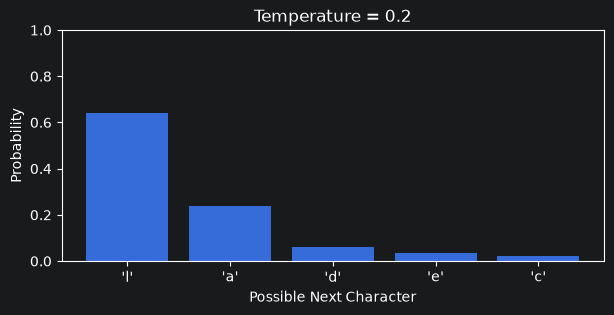

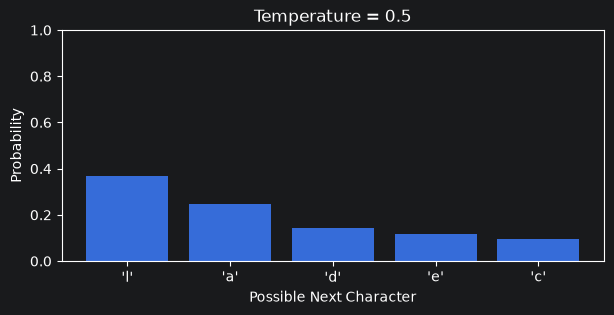

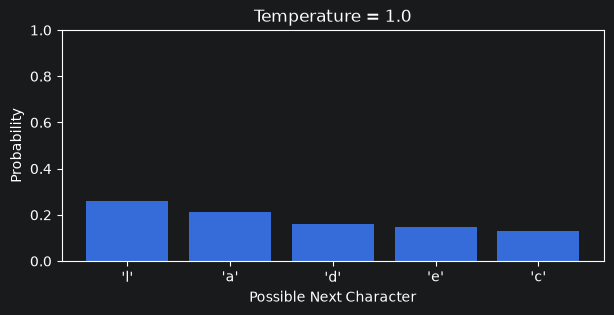

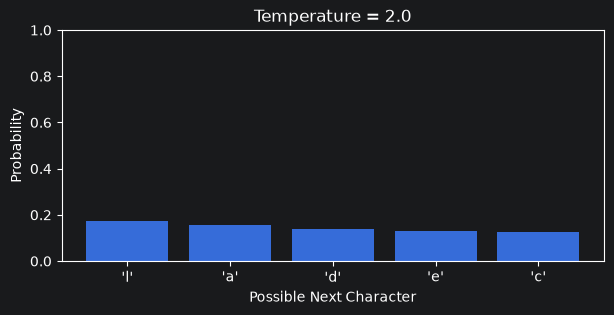

In [39]:
# ============================================================
# CELL 15C: VISUALIZE TEMPERATURE AND TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Visualize how temperature redistributes probability
# across possible next characters.
#
# We select the five highest-scoring tokens at temperature 1.
# Then compare their probabilities at different temperatures.
#
# The model and logits remain unchanged.
# ============================================================



temperatures = [0.2, 0.5, 1.0, 2.0] #[0.1, 0.5, 1.0, 2.0, 5.0]
top_ids = torch.topk(temperature_logits, k=5).indices

for temperature in temperatures:

    probs = F.softmax(temperature_logits / temperature, dim=-1)
    selected_probs = probs[top_ids].detach().cpu().numpy()
    labels = [repr(itos[i.item()]) for i in top_ids]

    plt.figure(figsize=(7, 3))
    plt.bar(labels, selected_probs)
    plt.title(f"Temperature = {temperature}")
    plt.xlabel("Possible Next Character")
    plt.ylabel("Probability")
    plt.ylim(0, 1)
    plt.show()

In [40]:
# ============================================================
# CELL 15D: OBSERVE GENERATION VARIETY
# ============================================================
# Purpose:
# Generate multiple responses at each temperature.
#
# Low temperature:
#   Repeated generations tend to be similar.
#
# High temperature:
#   Repeated generations tend to be more diverse.
#
# We keep the model, prompt, and output length constant.
# ============================================================

prompt = "students "

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.01, 0.1, 0.5, 1.0, 2.0]

for temperature in temperatures:

    print("\n" + "=" * 65)
    print(f"TEMPERATURE: {temperature}")
    print("=" * 65)

    for run in range(3):
        response = generate_text(
            model,
            prompt,
            max_new_tokens=60,
            temperature=temperature)

        print(f"Run {run + 1}: {response!r}")


TEMPERATURE: 0.2
Run 1: 'students develop artificial intelligence systems.\nlanguage models pre'
Run 2: 'students learn python programming.\nstudents develop artificial intell'
Run 3: 'students are building useful software products.\nsmall language models'

TEMPERATURE: 0.5
Run 1: 'students experiment with language models.\nartificial intelligence can'
Run 2: 'students are building useful software products.\nsmall language models'
Run 3: 'students build django applications.\nstudents learn python programming'

TEMPERATURE: 1.0
Run 1: 'students develop artificial intelligence systems.\nlanguage models pre'
Run 2: 'students learn python programming.\nstudents develop artificial intell'
Run 3: 'students are building useful software products.\nsmall language models'

TEMPERATURE: 2.0
Run 1: 'students develop artificial intelligence systems.\nlanguage models pre'
Run 2: 'students learn python programming.\nstudentdents experiment with la le'
Run 3: 'students cre.\nstudents create innovativ

## Step 1.3: Test Generation Temperatures

max_new_tokens=60

| Temperature | Run   | Generated Text                                                           | Observations |
|-------------|-------|--------------------------------------------------------------------------|---------|
| **0.2**     | Run 1 | 'students develop artificial intelligence systems.\nlanguage models pre' | Easy to get the same prediction result
| **0.2**     | Run 2 | 'students are building useful software products.\nsmall language models' |
| **0.2**     | Run 3 | 'students are building useful software products.\nsmall language models' |
| **0.5**     | Run 1 | 'students are building useful software products.\nsmall language models' | prediction result not the same anymore
| **0.5**     | Run 2 | 'students create innovative startup applications.\ndjango applications ' |
| **0.5**     | Run 3 | 'students experiment with language models.\nartificial intelligence can' |
| **1.0**     | Run 1 | 'students learn python programming.\nstudents develop artificial intell' | Similart with T=0.5 case
| **1.0**     | Run 2 | 'students are building useful software products.\nsmall language models' |
| **1.0**     | Run 3 | 'students build django applications.\nstudents learn python programming' |
| **2.0**     | Run 1 | 'students s create innovative y ofparacmeters.\nthe university offers c' | Model start to predict words that has no meaning
| **2.0**     | Run 2 | 'students experiment with language models.\nartificial intelligence cah' |
| **2.0**     | Run 3 | 'students build django applications.\nstudents learn python programming' |

## Step 1.4: Analysis

Answer the following in one to two sentences each:

1. Which architecture contained the most trainable parameters?<br>
Model 5 with largest Embedding Dimension, Transformer Layers, and Feed-Forward Dimension has the largest trainable parameter value.

2. Did increasing the number of attention heads increase the total parameter count?<br>
No, attention heads number only divides the embedding dimension into individual head. It only affect the individual head size but not the total parameter.
3. Did increasing the number of Transformer layers improve generated text?<br>
Yes, increasing the number of Transformer layers significantly improves text quality by allowing the network to capture complex, high-level abstractions and long-range logical reasoning.
4. Which architecture required the most training time?<br>
Model 5 requires the longest training time because it has largest total parameter.
5. Did the model with the most parameters necessarily generate the best text?<br>
No really for all situation. Model 4 with the smaller Embedding Dimension and Feed-Forward Dimension has the similar training loss value after training. When the dataset for training is small, the behavior of the larger model will behave similar after training.
6. How did changing temperature affect the generated responses?<br>
For low temperature, the model predict similar sentence output without any randomness. When temperature increase, the predicted sentence start to have variance and all the sentences are still meaningful. When temperature is too high, the predicted sentence sometimes doesn't make sense and the model often predict non-meaningful words.

In [41]:
# SAVE AND RELOAD OUR MODEL

CHECKPOINT_PATH = Path("tiny_transformer.pt")

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")
print(generate_text(reloaded_model, "students ", max_new_tokens=100))

Model reloaded successfully.
students are building useful software products.
small language models can run on local computers.
students bu


# Part 2: Retrieval-Augmented Generation Using Our SLM

In [42]:
TOP_K = 1
TEMPERATURE = 0.5
MAX_OUTPUT_TOKENS = 50
MAX_NEW_TOKENS = MAX_OUTPUT_TOKENS


def normalize_to_vocab(text):
    """Lowercase text and replace unsupported characters instead of silently deleting them."""
    text = str(text).lower()
    return "".join(ch if ch in stoi else " " for ch in text)


@torch.no_grad()
def generate_completion(
    active_model,
    prompt,
    max_new_tokens=MAX_OUTPUT_TOKENS,
    temperature=TEMPERATURE,
    do_sample=False,
    stop_at_newline=True,
):
    """Return only the generated continuation, stopping at the first newline."""
    if temperature <= 0:
        raise ValueError("temperature must be greater than zero")

    prompt = normalize_to_vocab(prompt)
    prompt_ids = encode(prompt)
    if not prompt_ids:
        raise ValueError("The prompt contains no characters from the model vocabulary.")

    input_ids = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    generated_ids = []
    newline_id = stoi.get("\n")
    was_training = active_model.training
    active_model.eval()

    try:
        for _ in range(max_new_tokens):
            context = input_ids[:, -active_model.context_length:]
            logits = active_model(context)
            if isinstance(logits, tuple):
                logits = logits[0]
            next_logits = logits[:, -1, :]

            if do_sample:
                probs = F.softmax(next_logits / temperature, dim=-1)
                next_id = torch.multinomial(probs, num_samples=1)
            else:
                next_id = torch.argmax(next_logits, dim=-1, keepdim=True)

            token_id = int(next_id.item())
            if stop_at_newline and newline_id is not None and token_id == newline_id:
                break

            generated_ids.append(token_id)
            input_ids = torch.cat([input_ids, next_id], dim=1)
    finally:
        active_model.train(was_training)

    return decode(generated_ids).strip()


def ask_llm(
    prompt,
    system=None,
    max_new_tokens=MAX_OUTPUT_TOKENS,
    model_to_use=None,
):
    """Generate one line with the selected model. `system` is not used by this custom SLM."""
    active_model = model if model_to_use is None else model_to_use
    start = time.perf_counter()
    response_text = generate_completion(
        active_model,
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=TEMPERATURE,
        do_sample=False,
        stop_at_newline=True,
    )
    return response_text, time.perf_counter() - start


In [43]:
import pandas as pd

documents = [
    {"id": "D1",  "title": "What is dog", "text": "dog is animal."},
    {"id": "D2",  "title": "What is cat", "text": "cat is animal."},
    {"id": "D3",  "title": "How are you", "text": "i am ok."},
    {"id": "D4",  "title": "When is noon", "text": "noon is twelve pm."},
    {"id": "D5",  "title": "What is apple", "text": "apple is a fruit."},
    {"id": "D6",  "title": "What is banana", "text": "banana is a fruit."},
    {"id": "D7",  "title": "What is milk", "text": "milk is a drink."},
    {"id": "D8",  "title": "What is water", "text": "water is a drink."},
    {"id": "D9",  "title": "What is bread", "text": "bread is food."},
    {"id": "D10", "title": "What is rice", "text": "rice is food."},
    {"id": "D11", "title": "What is a bird", "text": "a bird can fly."},
    {"id": "D12", "title": "What is a fish", "text": "a fish lives in water."},
    {"id": "D13", "title": "Where do dogs live", "text": "dogs can live in homes."},
    {"id": "D14", "title": "What do cats drink", "text": "cats drink water."},
    {"id": "D15", "title": "What do dogs eat", "text": "dogs eat meat and food."},
    {"id": "D16", "title": "What color is grass", "text": "grass is green."},
    {"id": "D17", "title": "What color is snow", "text": "snow is white."},
    {"id": "D18", "title": "What color is the sky", "text": "the sky is blue."},
    {"id": "D19", "title": "How many legs has a dog", "text": "a dog has four legs."},
    {"id": "D20", "title": "How many days in a week", "text": "there are seven days."},
    {"id": "D21", "title": "How many months in a year", "text": "there are twelve months."},
    {"id": "D22", "title": "What comes after monday", "text": "tuesday comes after monday."},
    {"id": "D23", "title": "What comes after friday", "text": "saturday comes after friday."},
    {"id": "D24", "title": "When does the sun rise", "text": "the sun rises in the morning."},
    {"id": "D25", "title": "When does the sun set", "text": "the sun sets in the evening."},
    {"id": "D26", "title": "What is noon", "text": "noon is twelve pm."},
    {"id": "D27", "title": "What is night", "text": "night is a time for sleep."},
    {"id": "D28", "title": "What is rain", "text": "rain is water from clouds."},
    {"id": "D29", "title": "What is snow", "text": "snow is frozen water."},
    {"id": "D30", "title": "What is fire", "text": "fire gives heat and light."},
    {"id": "D31", "title": "What is a car", "text": "a car is a vehicle."},
    {"id": "D32", "title": "What is a bus", "text": "a bus carries people."},
    {"id": "D33", "title": "What is a train", "text": "a train runs on tracks."},
    {"id": "D34", "title": "What is a phone", "text": "a phone helps people communicate."},
    {"id": "D35", "title": "What is a computer", "text": "a computer processes information."},
    {"id": "D36", "title": "What is a book", "text": "a book contains written words."},
    {"id": "D37", "title": "What is a school", "text": "a school is a place to learn."},
    {"id": "D38", "title": "What is a teacher", "text": "a teacher helps students learn."},
    {"id": "D39", "title": "What is a student", "text": "a student learns new things."},
    {"id": "D40", "title": "What is a friend", "text": "a friend is someone you trust."},
    {"id": "D41", "title": "How do you say hello", "text": "hello is a greeting."},
    {"id": "D42", "title": "How do you say goodbye", "text": "goodbye is used when leaving."},
    {"id": "D43", "title": "Why do people sleep", "text": "sleep helps the body rest."},
    {"id": "D44", "title": "Why do plants need water", "text": "plants need water to grow."},
    {"id": "D45", "title": "What do plants need", "text": "plants need water and sunlight."},
    {"id": "D46", "title": "What is the earth", "text": "earth is the planet we live on."},
    {"id": "D47", "title": "What is the moon", "text": "the moon moves around the earth."},
    {"id": "D48", "title": "What is the sun", "text": "the sun gives earth light and heat."},
    {"id": "D49", "title": "How are you today", "text": "i am doing well today."},
    {"id": "D50", "title": "What time is noon", "text": "noon is twelve pm."}
]


# documents = [
#     {"id": "D1", "title": "leg", "text": "dog has four legs and one big month."},
#     {"id": "D2", "title": "play", "text": "dog likes to play."},
#     {"id": "D3", "title": "food", "text": "dog eats chicken everyday."},
#     {"id": "D4", "title": "sleep", "text": "dog sleep ten hours per day."},
#     {"id": "D5", "title": "eye", "text": "dog eye is partial color blinded."},
# ]
print(pd.DataFrame(documents).to_string(index=False))

# import pandas as pd
# documents = [
#     {"id": "D1", "title": "dog", "text": "dog has four legs."},
#     {"id": "D2", "title": "chicken", "text": "chicken has two legs and two wings."},
#     {"id": "D3", "title": "fish", "text": "fish has several fins but no leg"},
#     {"id": "D4", "title": "ant", "text": "ant has six legs."},
#     {"id": "D5", "title": "dragon", "text": "dragon has four legs and two wings."},
# ]
# print(pd.DataFrame(documents).to_string(index=False))

 id                     title                                text
 D1               What is dog                      dog is animal.
 D2               What is cat                      cat is animal.
 D3               How are you                            i am ok.
 D4              When is noon                  noon is twelve pm.
 D5             What is apple                   apple is a fruit.
 D6            What is banana                  banana is a fruit.
 D7              What is milk                    milk is a drink.
 D8             What is water                   water is a drink.
 D9             What is bread                      bread is food.
D10              What is rice                       rice is food.
D11            What is a bird                     a bird can fly.
D12            What is a fish              a fish lives in water.
D13        Where do dogs live             dogs can live in homes.
D14        What do cats drink                   cats drink water.
D15       

In [44]:
# Text vectorization.
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
document_matrix = vectorizer.fit_transform([d["title"] + " " + d["text"] for d in documents])
print("Document matrix shape:", document_matrix.shape)
print("Vocabulary features:", len(vectorizer.vocabulary_))


Document matrix shape: (50, 245)
Vocabulary features: 245


In [45]:
# Get vocabulary features in their corresponding column order.
features = vectorizer.get_feature_names_out()

# Convert the sparse matrix into a readable DataFrame.
document_df = pd.DataFrame(
    document_matrix.toarray(),
    columns=features,
    index=[d["id"] for d in documents]    # Check out Cell 5 to see the contents of our document
)

# Display the complete matrix.
print("=" * 80)
print("TF-IDF DOCUMENT MATRIX")
print("=" * 80)

print("Matrix Shape:", document_df.shape)

# display(document_df.round(3))

TF-IDF DOCUMENT MATRIX
Matrix Shape: (50, 245)


In [46]:
# Build RAG workflow
from sklearn.metrics.pairwise import cosine_similarity


def retrieve(query, top_k=1, min_score=0.01):
    """Return the top matching documents and their cosine-similarity scores."""
    query = normalize_to_vocab(query)
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, document_matrix)[0]
    indices = scores.argsort()[::-1][:max(1, int(top_k))]
    return [
        {**documents[i], "score": float(scores[i])}
        for i in indices
        if scores[i] >= min_score
    ]


def build_rag_prompt(question, matches, model_to_use=None):
    """Place retrieved text before the question and enforce the model context limit."""
    active_model = model if model_to_use is None else model_to_use
    context_length = active_model.context_length
    question = normalize_to_vocab(question).strip()
    question_part = question + "\n"

    # Reserve space for the question and one separator character.
    document_budget = max(0, context_length - len(question_part) - 1)
    document_parts = [
        normalize_to_vocab(d.get("text", "")).strip()
        for d in matches
        if d.get("text", "").strip()
    ]
    document = " ".join(document_parts)

    # Keep the beginning of the highest-ranked evidence, where short facts often start.
    document = document[:document_budget]
    prompt = document + "\n" + question_part if document else question_part
    return prompt[-context_length:]


def rag_answer(question, top_k=1, model_to_use=None):
    start = time.perf_counter()
    active_model = model if model_to_use is None else model_to_use
    evidence = retrieve(question, top_k=top_k)
    prompt = build_rag_prompt(question, evidence, model_to_use=active_model)
    answer, generation_seconds = ask_llm(
        prompt,
        max_new_tokens=MAX_OUTPUT_TOKENS,
        model_to_use=active_model,
    )
    return {
        "question": question,
        "prompt": prompt,
        "answer": answer,
        "documents": evidence,
        "total_seconds": time.perf_counter() - start,
        "generation_seconds": generation_seconds,
    }


In [47]:
# Testing
QUESTION = "what is dog"
TOP_K = 2

baseline_answer, baseline_seconds = ask_llm(QUESTION)
result = rag_answer(QUESTION, top_k=TOP_K)      # Now working on the actual RAG implementation.

print("QUESTION:", QUESTION)
print("\nWITHOUT RAG:", baseline_answer)
print(f"Total time: {baseline_seconds:.2f}s")
print("\nWITH RAG:", result["answer"])
print("SOURCES:", [d["id"] for d in result["documents"]])
print(f"Total RAG time: {result['total_seconds']:.2f}s")

QUESTION: what is dog

WITHOUT RAG: usly denerate text.
Total time: 0.01s

WITH RAG: students develop artificial intelligence systems.
SOURCES: ['D1', 'D19']
Total RAG time: 0.01s


In [48]:
# Step 2.2: Test the SLM Without RAG
test_questions = [
    "what is apple",
    "how many days in a week",
    "what is the earth",
    "what is teacher",
    "what do cats eat"
]

non_RAG_rows = []


for question in test_questions:
    baseline_answer, baseline_seconds = ask_llm(question)
    non_RAG_rows.append({"question": question,
                 "answer": baseline_answer, "seconds": round(baseline_seconds, 4)})

results_non_RAG = pd.DataFrame(non_RAG_rows)
results_non_RAG

,question,answer,seconds
0,what is apple,dinghe achine learning research.,0.0093
1,how many days in a week,.,0.0007
2,what is the earth,.,0.0006
3,what is teacher,arn fres artificial intelligence.,0.0092
4,what do cats eat,ions.,0.0016


In [49]:
# Step 2.3: Apply RAG to the Same SLM
TOP_K = [1, 2, 3, 5]
RAG_rows = []

def response_Q(question, answer):
    """
    Evaluate response quality on a 1-10 scale using simple heuristics.
    """
    question = question.lower().strip()
    answer = answer.lower().strip()

    if not answer:
        return 1

    score = 5.0

    # Reward answers that share words with the question
    question_words = set(question.split())
    answer_words = set(answer.split())

    if question_words:
        overlap = len(question_words & answer_words) / len(question_words)
        score += 3 * overlap

    # Penalize very short or excessively long answers
    if len(answer) < 3:
        score -= 2
    elif len(answer) > 200:
        score -= 1

    # Penalize repetitive answers
    words = answer.split()
    if len(words) >= 4 and len(set(words)) / len(words) < 0.5:
        score -= 2

    return max(1, min(10, round(score)))



for question in test_questions:
    for top_k in TOP_K:
        r = rag_answer(question, top_k=top_k)
        predicted_quality = response_Q(question, r["answer"])
        RAG_rows.append({"question": question, "TOP_K":top_k, "retrieved_ids": ", ".join(d["id"] for d in r["documents"]),
                     "answer": r["answer"], "seconds": round(r["total_seconds"], 4), "Q": predicted_quality})

results_RAG = pd.DataFrame(RAG_rows)
results_RAG

,question,TOP_K,retrieved_ids,answer,seconds,Q
0,what is apple,1,D5,the university offers courses in informatics.,0.0165,5
1,what is apple,2,D5,the university offers courses in informatics.,0.0145,5
2,what is apple,3,D5,the university offers courses in informatics.,0.0133,5
3,what is apple,5,D5,the university offers courses in informatics.,0.0136,5
4,how many days in a week,1,D20,language models predict the next token.,0.0120,5
5,how many days in a week,2,D20,language models predict the next token.,0.0124,5
6,how many days in a week,3,D20,language models predict the next token.,0.0114,5
7,how many days in a week,5,D20,language models predict the next token.,0.0117,5
8,what is the earth,1,D46,icial intelligence students are building usefu...,0.0143,5
9,what is the earth,2,"D46, D47",icial intelligence students are building usefu...,0.0141,5


## Step 2.4: Analysis

1. **Did retrieval change the prompt?**
Yes. RAG appends retrieved text before the question, but the SLM is not guaranteed to use that text correctly.
2. **Did RAG improve factual accuracy?**
Not reliably. This scratch-built character-level model was not trained to follow evidence-grounded question-answering instructions.
3. **Does retrieving more documents always help?**
No. With a 32-character context, adding documents can crowd out relevant evidence or cause truncation.
4. **How does context length affect results?**
The evidence plus the question must fit in the model's context window; in many cases, 32 characters is too short.
5. **Why does RAG behave differently from a pretrained instruction model?**
This SLM learns character continuations from a small corpus and has not learned the instruction-following behavior expected by a RAG pipeline.


# Part 3: Multi-Model Routing Strategy

In [50]:
# Step 3.1: Create Your Own Fine-Tuning Examples

training_pairs = [
    ("what is dog",
     "dog is animal."),

    ("what is cat",
     "cat is animal."),

    ("how are you",
     "i am ok."),

    ("when is noon",
     "noon is twelve pm."),

    ("what is apple",
     "apple is a fruit."),

    ("what is banana",
     "banana is a fruit."),

    ("what is milk",
     "milk is a drink."),

    ("what is water",
     "water is a drink."),

    ("what is bread",
     "bread is food."),

    ("what is rice",
     "rice is food."),

    ("what is a bird",
     "a bird can fly."),

    ("what is a fish",
     "a fish lives in water."),

    ("where do dogs live",
     "dogs can live in homes."),

    ("what do cats drink",
     "cats drink water."),

    ("what do dogs eat",
     "dogs eat meat and food."),

    ("what color is grass",
     "grass is green."),

    ("what color is snow",
     "snow is white."),

    ("what color is the sky",
     "the sky is blue."),

    ("how many legs has a dog",
     "a dog has four legs."),

    ("how many days in a week",
     "there are seven days."),

    ("how many months in a year",
     "there are twelve months."),

    ("what comes after monday",
     "tuesday comes after monday."),

    ("what comes after friday",
     "saturday comes after friday."),

    ("when does the sun rise",
     "the sun rises in the morning."),

    ("when does the sun set",
     "the sun sets in the evening."),

    ("what is noon",
     "noon is twelve pm."),

    ("what is night",
     "night is a time for sleep."),

    ("what is rain",
     "rain is water from clouds."),

    ("what is snow",
     "snow is frozen water."),

    ("what is fire",
     "fire gives heat and light."),

    ("what is a car",
     "a car is a vehicle."),

    ("what is a bus",
     "a bus carries people."),

    ("what is a train",
     "a train runs on tracks."),

    ("what is a phone",
     "a phone helps people communicate."),

    ("what is a computer",
     "a computer processes information."),

    ("what is a book",
     "a book contains written words."),

    ("what is a school",
     "a school is a place to learn."),

    ("what is a teacher",
     "a teacher helps students learn."),

    ("what is a student",
     "a student learns new things."),

    ("what is a friend",
     "a friend is someone you trust."),

    ("how do you say hello",
     "hello is a greeting."),

    ("how do you say goodbye",
     "goodbye is used when leaving."),

    ("why do people sleep",
     "sleep helps the body rest."),

    ("why do plants need water",
     "plants need water to grow."),

    ("what do plants need",
     "plants need water and sunlight."),

    ("what is the earth",
     "earth is the planet we live on."),

    ("what is the moon",
     "the moon moves around the earth."),

    ("what is the sun",
     "the sun gives earth light and heat."),

    ("how are you today",
     "i am doing well today."),

    ("what time is noon",
     "noon is twelve pm.")
]

In [51]:
# Step 3.2: Test the SLM Before Fine-Tuning

probe_questions = [
    "what is apple",                    # Seen
    "how many days in a week",          # Seen
    "what is the earth",                # Seen
    "what is teacher",                  # Unseen
    "what do cats eat"                  # Unseen
]

In [52]:
def format_prompt(question):
    """Compact question prefix; newline marks the point where the answer begins."""
    return normalize_to_vocab(question).strip() + "\n"


# Display the supervised fine-tuning dataset.
print("=" * 75)
print("SUPERVISED FINE-TUNING DATASET")
print("=" * 75)
print("Question-answer pairs:", len(training_pairs))
for i, (question, answer) in enumerate(training_pairs, start=1):
    print(f"{i:02d}. Q: {question} | A: {answer}")

print("\nEvaluation questions:")
for i, question in enumerate(probe_questions, start=1):
    status = "SEEN" if question in [q for q, _ in training_pairs] else "UNSEEN"
    print(f"{i}. ({status}) {question}")


SUPERVISED FINE-TUNING DATASET
Question-answer pairs: 50
01. Q: what is dog | A: dog is animal.
02. Q: what is cat | A: cat is animal.
03. Q: how are you | A: i am ok.
04. Q: when is noon | A: noon is twelve pm.
05. Q: what is apple | A: apple is a fruit.
06. Q: what is banana | A: banana is a fruit.
07. Q: what is milk | A: milk is a drink.
08. Q: what is water | A: water is a drink.
09. Q: what is bread | A: bread is food.
10. Q: what is rice | A: rice is food.
11. Q: what is a bird | A: a bird can fly.
12. Q: what is a fish | A: a fish lives in water.
13. Q: where do dogs live | A: dogs can live in homes.
14. Q: what do cats drink | A: cats drink water.
15. Q: what do dogs eat | A: dogs eat meat and food.
16. Q: what color is grass | A: grass is green.
17. Q: what color is snow | A: snow is white.
18. Q: what color is the sky | A: the sky is blue.
19. Q: how many legs has a dog | A: a dog has four legs.
20. Q: how many days in a week | A: there are seven days.
21. Q: how many months

In [53]:
def answer_question(model, question, max_new_tokens=MAX_NEW_TOKENS):
    """Generate only the answer continuation; stop at the answer-ending newline."""
    prompt = format_prompt(question)
    return generate_completion(
        model,
        prompt,
        max_new_tokens=max_new_tokens,
        temperature=1.0,
        do_sample=False,
        stop_at_newline=True,
    )


question = probe_questions[0]
print("QUESTION:", question)
print("FORMATTED PROMPT:", repr(format_prompt(question)))
print("GENERATED ANSWER:", answer_question(model, question))


QUESTION: what is apple
FORMATTED PROMPT: 'what is apple\n'
GENERATED ANSWER: artificial intelligence can generate text.


In [54]:
# Step 3.2: Test the SLM Before Fine-Tuning
import copy


before_answers = {}
before_rows = []

for question in probe_questions:
    before_answers[question] = answer_question(model, question)
    before_rows.append({"question": question,
                 "Response Before Fine-Tuning": before_answers[question]})

results_before_rows = pd.DataFrame(before_rows)
results_before_rows


,question,Response Before Fine-Tuning
0,what is apple,artificial intelligence can generate text.
1,how many days in a week,language models predict the next token.
2,what is the earth,ts artup applicationsor mation applications.
3,what is teacher,students create innovative startup applications.
4,what do cats eat,the university offers courses in informatics.


In [55]:
# Step 3.3: Fine-Tune the SLM

CHECKPOINT_PATH = Path("tiny_transformer.pt")

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")


Model reloaded successfully.


In [56]:
# Build one next-character training example per answer character.
# This prevents suffix-truncation from deleting the beginning of long answers.
train_examples = []

for question, answer in training_pairs:
    prompt_ids = encode(format_prompt(question))
    answer_text = normalize_to_vocab(answer.strip()) + "\n"  # newline is the end-of-answer marker
    answer_ids = encode(answer_text)

    if not prompt_ids:
        raise ValueError(f"Prompt has no supported characters: {question!r}")
    if not answer_ids:
        raise ValueError(f"Answer has no supported characters: {answer!r}")

    for answer_position, target_id in enumerate(answer_ids):
        # Match inference exactly: use the most recent context_length chars before the target.
        context_ids = (prompt_ids + answer_ids[:answer_position])[-CONTEXT_LENGTH:]
        input_tensor = torch.tensor([context_ids], dtype=torch.long, device=DEVICE)
        target_tensor = torch.tensor([target_id], dtype=torch.long, device=DEVICE)
        train_examples.append((input_tensor, target_tensor))

print(f"Question-answer pairs: {len(training_pairs)}")
print(f"Character-level next-token examples: {len(train_examples)}")
print(f"Context length: {CONTEXT_LENGTH}")
print("Each example predicts exactly one next character from its preceding context.")


Question-answer pairs: 50
Character-level next-token examples: 1185
Context length: 32
Each example predicts exactly one next character from its preceding context.


In [57]:
# ============================================================
# CELL 9: SAVE A SNAPSHOT OF PRETRAINED WEIGHTS
# ============================================================
# Purpose: Prove fine-tuning changes weights numerically.
# Snapshot ONE tensor, not the whole model, to conserve RAM.
# ============================================================
parameter_name, parameter = next((name, p) for name, p in reloaded_model.named_parameters() if p.requires_grad)
weights_before = parameter.detach().clone()
print("Tracking:", parameter_name, "| Shape:", tuple(weights_before.shape))

Tracking: token_embedding.weight | Shape: (27, 48)


In [58]:
import copy
import random
import time
import torch
import torch.nn.functional as F

FINETUNING_LEARNING_RATE = 3e-4
FINETUNING_STEPS = min(TRAINING_STEPS, 5000)

model_fin_tuned = copy.deepcopy(reloaded_model).to(DEVICE)
optimizer = torch.optim.AdamW(
    model_fin_tuned.parameters(),
    lr=FINETUNING_LEARNING_RATE,
)


@torch.no_grad()
def evaluate_finetuning_loss(active_model, examples):
    """Mean cross-entropy across all character targets, not just the last example."""
    was_training = active_model.training
    active_model.eval()
    losses = []
    try:
        for context_ids, target_id in examples:
            logits = active_model(context_ids)
            if isinstance(logits, tuple):
                logits = logits[0]
            losses.append(F.cross_entropy(logits[:, -1, :], target_id).item())
    finally:
        active_model.train(was_training)
    return float(np.mean(losses))


initial_loss = evaluate_finetuning_loss(model_fin_tuned, train_examples)
loss_history = []
start = time.perf_counter()
model_fin_tuned.train()

for step in range(FINETUNING_STEPS):
    # Random sampling avoids tying the printed loss to the same fixed sequence of answers.
    example_index = random.randrange(len(train_examples))
    input_ids, target_ids = train_examples[example_index]

    optimizer.zero_grad(set_to_none=True)
    logits = model_fin_tuned(input_ids)
    if isinstance(logits, tuple):
        logits = logits[0]
    loss = F.cross_entropy(logits[:, -1, :], target_ids)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_fin_tuned.parameters(), max_norm=1.0)
    optimizer.step()
    loss_history.append(loss.item())

    if (step + 1) % 100 == 0 or step == 0 or step + 1 == FINETUNING_STEPS:
        window = loss_history[-100:]
        print(
            f"Step {step + 1}/{FINETUNING_STEPS} | "
            f"Mean loss over last {len(window)} updates: {np.mean(window):.4f}"
        )

elapsed = time.perf_counter() - start
final_loss = evaluate_finetuning_loss(model_fin_tuned, train_examples)

weights_updated = any(
    not torch.equal(base_param.detach(), tuned_param.detach())
    for base_param, tuned_param in zip(reloaded_model.parameters(), model_fin_tuned.parameters())
)

print("\nFINE-TUNING COMPLETED")
print("Question-answer pairs:", len(training_pairs))
print("Character targets:", len(train_examples))
print("Optimizer updates:", FINETUNING_STEPS)
print(f"Elapsed time: {elapsed:.1f} seconds")
print(f"Mean loss before fine-tuning: {initial_loss:.4f}")
print(f"Mean loss after fine-tuning:  {final_loss:.4f}")
print("Were weights updated?", weights_updated)


Step 1/5000 | Mean loss over last 1 updates: 17.0412
Step 100/5000 | Mean loss over last 100 updates: 6.6515
Step 200/5000 | Mean loss over last 100 updates: 4.9518
Step 300/5000 | Mean loss over last 100 updates: 3.0431
Step 400/5000 | Mean loss over last 100 updates: 3.0276
Step 500/5000 | Mean loss over last 100 updates: 2.3888
Step 600/5000 | Mean loss over last 100 updates: 3.0600
Step 700/5000 | Mean loss over last 100 updates: 2.4465
Step 800/5000 | Mean loss over last 100 updates: 2.6348
Step 900/5000 | Mean loss over last 100 updates: 2.7140
Step 1000/5000 | Mean loss over last 100 updates: 2.2451
Step 1100/5000 | Mean loss over last 100 updates: 2.1392
Step 1200/5000 | Mean loss over last 100 updates: 2.1823
Step 1300/5000 | Mean loss over last 100 updates: 2.0178
Step 1400/5000 | Mean loss over last 100 updates: 2.2605
Step 1500/5000 | Mean loss over last 100 updates: 2.5971
Step 1600/5000 | Mean loss over last 100 updates: 2.1525
Step 1700/5000 | Mean loss over last 100 upd

In [59]:
# ============================================================
# CELL 11: VERIFY THAT PARAMETERS CHANGED
# ============================================================
# Purpose: Show the numerical distinction between prompting
# (no weight changes) and fine-tuning (weight changes).
# ============================================================
weights_after = dict(model_fin_tuned.named_parameters())[parameter_name].detach()
change = (weights_after - weights_before).abs()
print("Tracked tensor:", parameter_name)
print("Mean absolute change:", change.mean().item())
print("Maximum absolute change:", change.max().item())
print("Elements changed:", int((change > 0).sum()), "/", change.numel())

Tracked tensor: token_embedding.weight
Mean absolute change: 0.021690942347049713
Maximum absolute change: 0.10149621963500977
Elements changed: 1296 / 1296


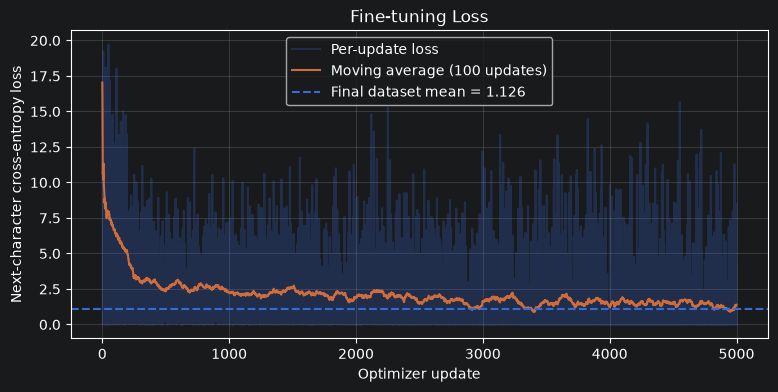

In [60]:
# Plot both the noisy per-update loss and a 100-update moving average.
plt.figure(figsize=(9, 4))
plt.plot(loss_history, alpha=0.25, label="Per-update loss")
window = min(100, len(loss_history))
smoothed = pd.Series(loss_history).rolling(window=window, min_periods=1).mean()
plt.plot(smoothed, label=f"Moving average ({window} updates)")
plt.axhline(final_loss, linestyle="--", label=f"Final dataset mean = {final_loss:.3f}")
plt.xlabel("Optimizer update")
plt.ylabel("Next-character cross-entropy loss")
plt.title("Fine-tuning Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [61]:
# Step 3.3: Test the SLM after Fine-Tuning
before_answers = {}
after_answers = {}

after_rows = []

for question in probe_questions:
    before_answers[question] = answer_question(model, question)
    after_answers[question] = answer_question(model_fin_tuned, question)
    after_rows.append({"question": question,
                "Response Before Fine-Tuning": before_answers[question],
                "Response After Fine-Tuning": after_answers[question]})

results_after_rows = pd.DataFrame(after_rows)
results_after_rows

,question,Response Before Fine-Tuning,Response After Fine-Tuning
0,what is apple,artificial intelligence can generate text.,aof a fri.
1,how many days in a week,language models predict the next token.,the moon searth learnd water trache are trache...
2,what is the earth,ts artup applicationsor mation applications.,a students learn.
3,what is teacher,students create innovative startup applications.,the s is a fritents is the pm.
4,what do cats eat,the university offers courses in informatics.,rime helps the mondametht.


In [62]:
num_finetuning_examples = len(training_pairs)
num_character_targets = len(train_examples)
total_parameters = sum(p.numel() for p in model_fin_tuned.parameters())

finetuning_results = {
    "SLM Architecture": type(model_fin_tuned).__name__,
    "Number of Parameters": f"{total_parameters:,}",
    "Question-Answer Pairs": num_finetuning_examples,
    "Character-Level Targets": num_character_targets,
    "Fine-Tuning Learning Rate": FINETUNING_LEARNING_RATE,
    "Fine-Tuning Steps": FINETUNING_STEPS,
    "Mean Training Loss Before Fine-Tuning": round(initial_loss, 4),
    "Mean Training Loss After Fine-Tuning": round(final_loss, 4),
    "Fine-Tuning Time": f"{elapsed:.1f} seconds",
    "Were Weights Updated?": "Yes" if weights_updated else "No",
}

from IPython.display import display, Markdown

table = "| Metric | Result |\n|---|---|\n"
for metric, result in finetuning_results.items():
    table += f"| {metric} | {result} |\n"
display(Markdown(table))


| Metric | Result |
|---|---|
| SLM Architecture | TinyTransformerLM |
| Number of Parameters | 60,795 |
| Question-Answer Pairs | 50 |
| Character-Level Targets | 1185 |
| Fine-Tuning Learning Rate | 0.0003 |
| Fine-Tuning Steps | 5000 |
| Mean Training Loss Before Fine-Tuning | 7.7327 |
| Mean Training Loss After Fine-Tuning | 1.1261 |
| Fine-Tuning Time | 9.6 seconds |
| Were Weights Updated? | Yes |


## Step 3.4: Analysis

1. Fine-tuning should change responses when the model learns the question-answer pattern, but every generated answer should be checked rather than assumed correct.
2. Lower training loss means the model predicts the fine-tuning targets better; it does not prove better factual accuracy on unseen questions.
3. Per-update loss can fluctuate because each update uses one character target. Use the moving average and the mean loss over all character targets for a meaningful comparison.
4. The fine-tuned model should have updated weights; the notebook compares the tuned parameters with the original model.
5. Yes. The model can still generate incorrect or unsupported answers, especially for questions or domains absent from fine-tuning.


In [63]:
# Compare baseline, RAG-only, fine-tuned-only, and combined RAG + fine-tuned SLM.
answer_rows = []

for question in probe_questions:
    baseline_answer = answer_question(model, question)
    rag_result = rag_answer(question, top_k=1, model_to_use=model)
    finetuned_answer = answer_question(model_fin_tuned, question)
    combined_result = rag_answer(question, top_k=1, model_to_use=model_fin_tuned)

    answer_rows.append({
        "question": question,
        "Baseline SLM": baseline_answer,
        "SLM + RAG": rag_result["answer"],
        "Fine-Tuned SLM": finetuned_answer,
        "RAG + Fine-Tuned SLM": combined_result["answer"],
        "Retrieved IDs": ", ".join(d["id"] for d in rag_result["documents"]),
    })

results_answer_rows = pd.DataFrame(answer_rows)
results_answer_rows


,question,Baseline SLM,SLM + RAG,Fine-Tuned SLM,RAG + Fine-Tuned SLM,Retrieved IDs
0,what is apple,artificial intelligence can generate text.,the university offers courses in informatics.,aof a fri.,the monet welht and livening.,D5
1,how many days in a week,language models predict the next token.,language models predict the next token.,the moon searth learnd water trache are trache...,the moneer tracher tres.,D20
2,what is the earth,ts artup applicationsor mation applications.,icial intelligence students are building usefu...,a students learn.,the m learnds.,D46
3,what is teacher,students create innovative startup applications.,the university offers courses in informatics.,the s is a fritents is the pm.,the moneer students in the mondands.,D38
4,what do cats eat,the university offers courses in informatics.,python is useful for machine learning research.,rime helps the mondametht.,the earthe s is a frit.,D14


## Performance Comparison: Baseline SLM, RAG, Fine-Tuning, and Combined RAG + Fine-Tuning

After rerunning the updated cells, compare the actual generated answers. Do not assign accuracy scores before checking answers against the expected facts and a held-out set.

| Evaluation Metric | Baseline SLM | SLM + RAG | Fine-Tuned SLM | RAG + Fine-Tuned SLM |
|:---|:---|:---|:---|:---|
| Retrieved document text included in prompt | No | Yes | No | Yes |
| Model weights updated for this condition | No | No | Yes | Fine-tuned weights are reused; retrieval itself adds no weight updates |
| Requires an external document store | No | Yes | No | Yes |
| Expected behavior with this scratch-built character-level model | Baseline continuation | May use evidence inconsistently | May learn trained Q&A patterns | Can combine learned Q&A patterns with evidence, but remains context-limited |


## Step 4.2: Final Analysis

1. **Which condition produced the most accurate responses?**
Fine-Tuned SLM will get the most accurate response when the question is in the fine-tuning docunment domain. Otherwise, all the model will react similar.
2. **Which approach updates model weights?**
Fine-tuning updates the SLM's parameters. RAG supplies retrieved text at inference time without updating weights.
3. **Which approach is easier to maintain when information changes?**
RAG, because the document collection can be updated independently of the model weights.
4. **Which approach suits frequently changing policies?**
RAG is usually easier to keep current, provided the model can correctly use retrieved evidence and cite or reproduce it.
5. **Can RAG and fine-tuning be combined?**
Yes. The model can be fine-tuned on context-plus-question-plus-answer examples and then supplied with newly retrieved context. This notebook's small character-level model may still be limited by its context length and lack of instruction-following capacity.


In [64]:
# ============================================================
# CELL 17: ASSIGNMENT 7 (PART-2) — CHANGE THE ARCHITECTURE
# ============================================================
# Purpose:
# Investigate how architectural choices affect parameter count.
#
# IMPORTANT:
# These models are newly initialized.
# They are NOT trained in this experiment.
#
# Change:
#   - Embedding dimension
#   - Number of attention heads
#   - Number of Transformer blocks
#   - Feed-forward dimension
#
# Observe:
#   - Total trainable parameters
#   - Whether changing attention heads changes parameter count
#   - How increasing layers changes model size
# ============================================================

experiments = [
    {"embedding_dim": 24, "num_heads": 2, "num_layers": 1, "feedforward_dim": 96},
    {"embedding_dim": 48, "num_heads": 2, "num_layers": 1, "feedforward_dim": 192},
    {"embedding_dim": 48, "num_heads": 4, "num_layers": 1, "feedforward_dim": 192},
    {"embedding_dim": 48, "num_heads": 2, "num_layers": 2, "feedforward_dim": 192},
    {"embedding_dim": 96, "num_heads": 4, "num_layers": 2, "feedforward_dim": 384}
]

for config in experiments:

    test_model = TinyTransformerLM(
        vocab_size=VOCAB_SIZE,
        context_length=CONTEXT_LENGTH,
        **config
    )

    parameters = sum(p.numel() for p in test_model.parameters())

    print(config)
    print(f"Parameters: {parameters:,}\n")





{'embedding_dim': 24, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 96}
Parameters: 9,363

{'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192}
Parameters: 32,523

{'embedding_dim': 48, 'num_heads': 4, 'num_layers': 1, 'feedforward_dim': 192}
Parameters: 32,523

{'embedding_dim': 48, 'num_heads': 2, 'num_layers': 2, 'feedforward_dim': 192}
Parameters: 60,795

{'embedding_dim': 96, 'num_heads': 4, 'num_layers': 2, 'feedforward_dim': 384}
Parameters: 232,155

